# Sentiment Analysis - YouTube Comments
**Nama**: Asep Haryana Saputra

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense, Bidirectional, Dropout, SpatialDropout1D, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm

print(f"TensorFlow Version: {tf.__version__}")

2026-02-10 18:47:35.033913: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-10 18:47:35.068938: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-10 18:47:36.069349: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow Version: 2.20.0


## 2. Data Loading & Preprocessing
**Target Classes**:
- 0: **Negative (Hujatan)**
- 1: **Positive (Apresiasi)**
- 2: **Spam (Promosi)**

In [2]:
# Nama file dataset
filename = 'dataset_youtube.csv'

if not os.path.exists(filename):
    raise FileNotFoundError(f"File {filename} not found! Please run the scraping script first.")

df = pd.read_csv(filename)
print(f"Loaded {len(df)} rows.")

# Auto-Labeling Function (Heuristic)
def auto_label(text):
    text = str(text).lower()
    
    # SPAM Keywords
    spam_keywords = ['cek ig', 'promo', 'jual', 'obat', 'peninggi', 'pelangsing', 'subscribe', 'sub4sub', 'mampir', 'channel', 'link bio', 'giveaway']
    if any(k in text for k in spam_keywords):
        return 2 # Spam
        
    # POSITIVE Keywords
    pos_keywords = ['bagus', 'keren', 'mantap', 'semangat', 'good', 'nice', 'love', 'thanks', 'terima kasih', 'bermanfaat', 'membantu', 'suka', 'cool', 'best', 'hebat', 'lanjutkan']
    if any(k in text for k in pos_keywords):
        return 1 # Positive
        
    # NEGATIVE Keywords (Example only, adjust as needed)
    neg_keywords = ['jelek', 'buruk', 'sampah', 'gagal', 'benci', 'hate', 'bad', 'stupid', 'idiot', 'bodoh', 'gajelas', 'malas', 'susah', 'ribet', 'unsub']
    if any(k in text for k in neg_keywords):
        return 0 # Negative
        
    return -1 # Unlabeled

df['label'] = df['text'].apply(auto_label)

# Drop unlabeled data for training
df_clean = df[df['label'] != -1].copy()
print(f"Labeled Data: {len(df_clean)} rows")
print(df_clean['label'].value_counts())

df_clean.head()

Loaded 15000 rows.
Labeled Data: 1216 rows
label
1    808
2    216
0    192
Name: count, dtype: int64


,cid,text,time,author,votes,photo,heart,label
55,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D51Zsxg5zU,Nice....,5 tahun yang lalu,@luqmanulhakim4201,3,https://yt3.ggpht.com/ytc/AIdro_m7z6UBUw1G4_Vi...,False,1
104,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D558YJI1Fc,Anjay keren bang,5 tahun yang lalu,@rafiunurul4983,1,https://yt3.ggpht.com/ytc/AIdro_lU5vkJxND_WDn2...,False,1
123,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D58ePLYtWc,Trailer lu kali ini bagus banget bang dari awa...,5 tahun yang lalu,@defrisaputro2662,1,https://yt3.ggpht.com/ytc/AIdro_nfgxglxGQFYmb9...,False,1
154,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D6wy7EbqDt,Asal usul kata anjay kan plesetan dari kata an...,5 tahun yang lalu,@doctorhape6730,1,https://yt3.ggpht.com/ytc/AIdro_lElgPiGCle5N-v...,False,1
209,UgwPwqqKva-HTdnXYTZ4AaABAg.9D50eRozUuj9D5CDDEwByz,ANJAY SUKA NICH YA GINI GINI WKWKWK,5 tahun yang lalu,@bdp2_08_aryasancakaputra8,0,https://yt3.ggpht.com/ytc/AIdro_lAVkSWUpj6Dopl...,False,1


In [3]:
# Text Cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text) # Remove URLs
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text) # Remove special chars
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df_clean['cleaned_text'] = df_clean['text'].apply(clean_text)
df_clean = df_clean[df_clean['cleaned_text'].str.len() > 3] # Min length filter

## 3. Tokenization & Splitting

In [4]:
VOCAB_SIZE = 5000
MAX_LENGTH = 100
EMBEDDING_DIM = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df_clean['cleaned_text'])

sequences = tokenizer.texts_to_sequences(df_clean['cleaned_text'])
padded_sequences = pad_sequences(sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')

X = padded_sequences
y = df_clean['label'].values

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (969, 100), Test shape: (243, 100)


## 4. Modeling (Bi-LSTM)

In [5]:
model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax') # 3 Output Classes
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

/home/asephs/venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1770724056.781900  732624 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3077 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Train
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[
        EarlyStopping(patience=5, restore_best_weights=True),
        ReduceLROnPlateau(factor=0.5, patience=2)
    ]
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9866 - loss: 0.0696 - val_accuracy: 0.8025 - val_loss: 0.6375 - learning_rate: 3.9063e-06
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9886 - loss: 0.0661 - val_accuracy: 0.8025 - val_loss: 0.6376 - learning_rate: 3.9063e-06
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9897 - loss: 0.0632 - val_accuracy: 0.8025 - val_loss: 0.6379 - learning_rate: 3.9063e-06
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9886 - loss: 0.0632 - val_accuracy: 0.8025 - val_loss: 0.6382 - learning_rate: 1.9531e-06
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9886 - loss: 0.0630 - val_accuracy: 0.8025 - val_loss: 0.6384 - learning_rate: 1.9531e-06
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9856 - loss: 0.0719 - val_accuracy: 0.8025 - val_loss: 0.6384 - learning_rate: 9.7656e-07


## 5. Evaluation

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
              precision    recall  f1-score   support

    Negative       0.59      0.71      0.64        38
    Positive       0.90      0.87      0.89       162
        Spam       0.76      0.72      0.74        43

    accuracy                           0.82       243
   macro avg       0.75      0.77      0.76       243
weighted avg       0.83      0.82      0.82       243



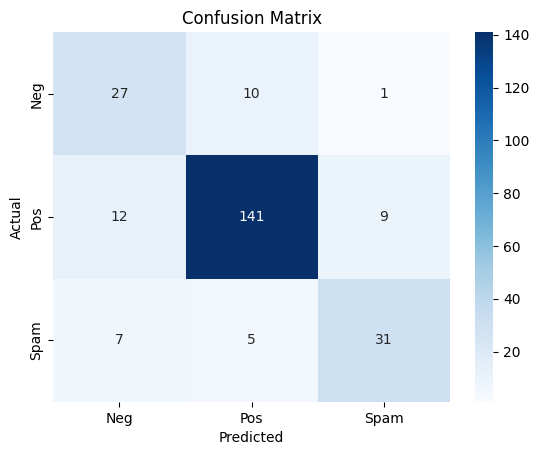

In [7]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive', 'Spam']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Neg', 'Pos', 'Spam'], yticklabels=['Neg', 'Pos', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()